<a href="https://colab.research.google.com/github/miguelreisnf/ProcessamentoDeImagens/blob/main/Quantizacao_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


In [3]:
arquivo = files.upload()
nome_arquivo = next(iter(arquivo))

img_bgr = cv2.imread(nome_arquivo)
if img_bgr is None:
    raise ValueError('Não foi possível carregar a imagem.')

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
altura = img_gray.shape[0]
largura = img_gray.shape[1]
print('Altura:', altura, '| Largura:', largura)
print('Tipo:', img_gray.dtype, '| Intervalo possível: 0 a 255')


Saving 6-APPS-PARA-GATOS-SE-DIVERTIREM.jpg to 6-APPS-PARA-GATOS-SE-DIVERTIREM.jpg
Altura: 720 | Largura: 1280
Tipo: uint8 | Intervalo possível: 0 a 255


In [4]:
def quantizar(imagem, bits):
    niveis = 2 ** bits
    passo = 256 // niveis

    pixels = imagem.astype(np.uint16)
    indices = pixels // passo

    quantizada = indices * 255 // (niveis - 1)
    return quantizada.astype(np.uint8)

img_1bit = quantizar(img_gray, 1)
img_2bits = quantizar(img_gray, 2)
img_4bits = quantizar(img_gray, 4)
img_8bits = quantizar(img_gray, 8)


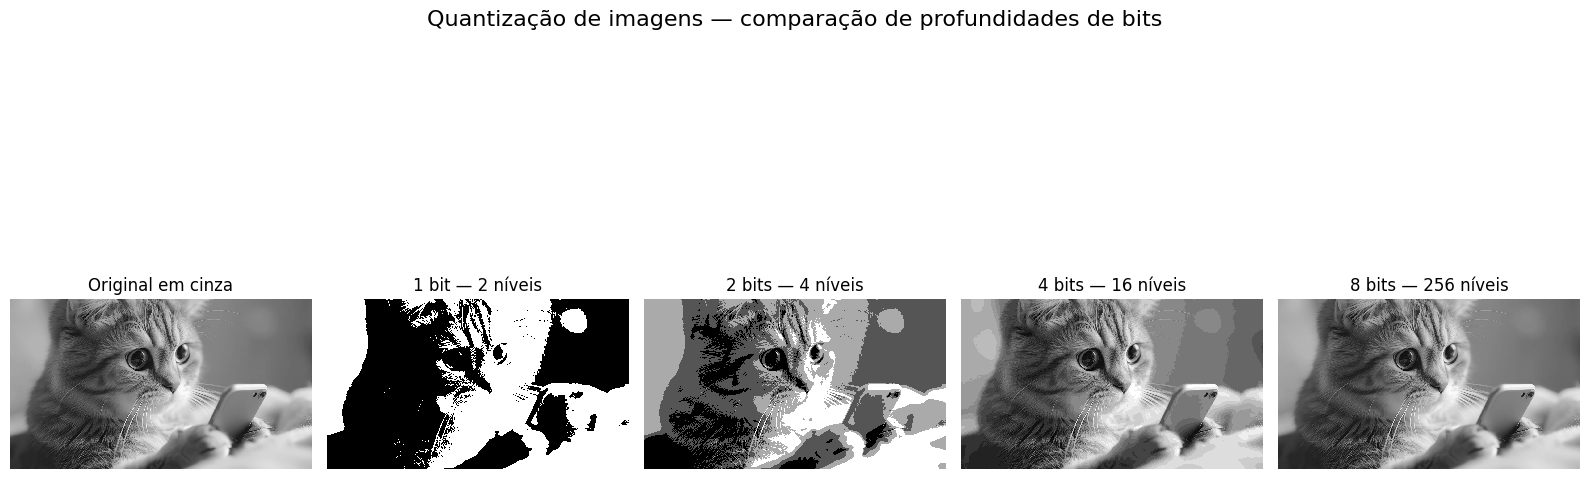

Figura salva como quantizacao.png


In [5]:
imagens = [img_gray, img_1bit, img_2bits, img_4bits, img_8bits]
titulos = ['Original em cinza', '1 bit — 2 níveis', '2 bits — 4 níveis',
           '4 bits — 16 níveis', '8 bits — 256 níveis']

fig = plt.figure(figsize=(16, 7))
for i in range(len(imagens)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(imagens[i], cmap='gray', vmin=0, vmax=255,
               interpolation='nearest')
    plt.title(titulos[i], fontsize=12)
    plt.axis('off')

plt.suptitle('Quantização de imagens — comparação de profundidades de bits', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('quantizacao.png', dpi=160, bbox_inches='tight')
plt.show()
print('Figura salva como quantizacao.png')


In [6]:
for bits, img in zip([1, 2, 4, 8], imagens[1:]):
    quantidade = len(np.unique(img))
    print(f'{bits} bits: {quantidade} níveis presentes de {2 ** bits} possíveis')
    assert quantidade <= 2 ** bits

assert np.array_equal(img_8bits, img_gray)
print('Verificado: a versão de 8 bits é igual à original em cinza.')


1 bits: 2 níveis presentes de 2 possíveis
2 bits: 4 níveis presentes de 4 possíveis
4 bits: 16 níveis presentes de 16 possíveis
8 bits: 250 níveis presentes de 256 possíveis
Verificado: a versão de 8 bits é igual à original em cinza.
